# Reconnaissance d'activités LiDAR sur MM-Fi avec un encodeur Point-MAE gelé

Méthodologie :

1. **Données** : MM-Fi LiDAR, 1080 séquences (4 environnements × 10 sujets × 27 actions), 297 frames à 10 Hz.
2. **Split** : cross-subject officiel (32 sujets d'entraînement, 8 de validation).
3. **Isolation de la personne** : suppression du fond statique de la pièce (voxels, appris sur les séquences d'entraînement de l'environnement), puis plus gros cluster DBSCAN.
4. **Fenêtres** : découpage de chaque séquence en fenêtres consécutives non chevauchantes (2 s par défaut) ; chaque fenêtre est normalisée (`pc_norm`) sur ses propres frames, puis tokenisée frame par frame (FPS + kNN).
5. **Features** : encodeur Point-MAE officiel pré-entraîné sur ShapeNet, gelé ; mean + max des tokens par frame, puis mean + max sur les frames de la fenêtre (1536-D).
6. **Classification** : SVM RBF sur les fenêtres ; évaluation par fenêtre et par séquence (vote majoritaire).

Seuls la normalisation `pc_norm` et le groupement FPS/kNN reprennent Point-MAE ; l'isolation de la personne et le découpage temporel sont propres à ce pipeline.

## 0 - Imports

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


PROJECT_DIR = Path.cwd()
MMFI_DATA_DIR = PROJECT_DIR / "data" / "MMFi_lidar_only" / "MMFi_Dataset"
MMFI_SRC_DIR = PROJECT_DIR / "mmfi-src"

if str(MMFI_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(MMFI_SRC_DIR))

import mmfi_dataset as mmfi


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = MMFI_SRC_DIR

print(f"MMFi data: {MMFI_DATA_DIR.resolve()}")
print(f"MMFi source: {MMFI_SRC_DIR.resolve()}")
print(f"Device: {DEVICE}")

MMFi data: C:\Users\mbonn\LIARA_2026_internship\data\MMFi_lidar_only\MMFi_Dataset
MMFi source: C:\Users\mbonn\LIARA_2026_internship\mmfi-src
Device: cuda


## 1 - Séquences et labels MM-Fi

In [2]:
sequences = mmfi.lister_sequences(MMFI_DATA_DIR)
action_codes = sorted(mmfi.ACTIONS)
action_to_label = {action: index for index, action in enumerate(action_codes)}

sequence_index = pd.DataFrame(
    [
        {
            "environment": environment,
            "subject": subject,
            "action": action,
            "label": action_to_label[action],
            "path": MMFI_DATA_DIR / environment / subject / action,
            "frames": len(mmfi.lister_frames(environment, subject, action, MMFI_DATA_DIR)),
        }
        for environment, subject, action in sequences
    ]
)

print(f"Sequences: {len(sequence_index)}")
print(f"Classes: {len(action_codes)}")
print(f"Frames per sequence: {sequence_index['frames'].unique().tolist()}")
sequence_index.head()

Sequences: 1080
Classes: 27
Frames per sequence: [297]


,environment,subject,action,label,path,frames
0,E01,S01,A01,0,C:\Users\mbonn\LIARA_2026_internship\data\MMFi...,297
1,E01,S01,A02,1,C:\Users\mbonn\LIARA_2026_internship\data\MMFi...,297
2,E01,S01,A03,2,C:\Users\mbonn\LIARA_2026_internship\data\MMFi...,297
3,E01,S01,A04,3,C:\Users\mbonn\LIARA_2026_internship\data\MMFi...,297
4,E01,S01,A05,4,C:\Users\mbonn\LIARA_2026_internship\data\MMFi...,297


## 2 - Split cross-subject

Split officiel S2 de MM-Fi : 32 sujets en entraînement, 8 en validation (S05, S10, …, S40, soit 2 par environnement). Le split cross-environment S3 (E01–E03 / E04) reste disponible via `SPLIT_SETTING`.

In [3]:
# MM-Fi official split settings (paper section 4 "Data Splits" + toolbox config.yaml):
#   S2 cross-subject     : 32 subjects for training, 8 for validation (2 per environment)
#   S3 cross-environment : E01-E03 for training, E04 for validation
SPLIT_SETTING = "cross_subject"  # "cross_subject" (S2) or "cross_environment" (S3)

OFFICIAL_VALIDATION_SUBJECTS = {"S05", "S10", "S15", "S20", "S25", "S30", "S35", "S40"}
OFFICIAL_VALIDATION_ENVIRONMENT = "E04"


def split_sequences(sequences, setting):
    """Split (environment, subject, action) tuples following the MM-Fi setting."""
    if setting == "cross_subject":
        def is_validation(sequence):
            return sequence[1] in OFFICIAL_VALIDATION_SUBJECTS
    elif setting == "cross_environment":
        def is_validation(sequence):
            return sequence[0] == OFFICIAL_VALIDATION_ENVIRONMENT
    else:
        raise ValueError(f"Unknown split setting: {setting!r}")

    train = [sequence for sequence in sequences if not is_validation(sequence)]
    validation = [sequence for sequence in sequences if is_validation(sequence)]
    return train, validation


train_sequences, validation_sequences = split_sequences(sequences, SPLIT_SETTING)

print(f"Split setting: {SPLIT_SETTING}")
print(f"Train: {len(train_sequences)} sequences / Validation: {len(validation_sequences)} sequences")
print(f"Train subjects: {len({sequence[1] for sequence in train_sequences})}")
print(f"Validation subjects: {sorted({sequence[1] for sequence in validation_sequences})}")
print(f"Validation environments: {sorted({sequence[0] for sequence in validation_sequences})}")


Split setting: cross_subject
Train: 864 sequences / Validation: 216 sequences
Train subjects: 32
Validation subjects: ['S05', 'S10', 'S15', 'S20', 'S25', 'S30', 'S35', 'S40']
Validation environments: ['E01', 'E02', 'E03', 'E04']


## 3 - Prétraitement

In [4]:
from sklearn.cluster import DBSCAN
from tqdm import tqdm


In [5]:
# MM-Fi frames are synchronised at 10 Hz for every modality.
LIDAR_SAMPLE_RATE_HZ = 10.0
# Window durations are expressed in seconds everywhere; frames are derived.
WINDOW_SECONDS = 2.0
# Consecutive windows: None -> stride = window duration (non-overlapping)
WINDOW_STRIDE_SECONDS = None


def seconds_to_frames(seconds):
    return max(1, int(round(seconds * LIDAR_SAMPLE_RATE_HZ)))


WINDOW_LENGTH = seconds_to_frames(WINDOW_SECONDS)

ENCODER_BATCH_FRAMES = 256
NUM_GROUP = 64
GROUP_SIZE = 32
VOXEL_SIZE = 0.10
STATIC_THRESHOLD = 0.80
DBSCAN_EPS = 0.25
DBSCAN_MIN_SAMPLES = 5
# Static background: "environment" (voxel occupancy over the training sequences of
# each environment, computed once) or "sequence" (recomputed on each sequence, ablation)
BACKGROUND_MODE = "environment"
BACKGROUND_FRAME_STRIDE = 15
# pc_norm-like normalisation before FPS/kNN (robust: median centroid, median max radius, clipped):
#   "window"     : statistics of the window's own frames -> every window is self-contained
#   "calibration": statistics of the first CALIBRATION_SECONDS of the sequence (causal, shared)
#   "sequence"   : statistics of the whole sequence (non-causal, ablation)
#   "frame"      : each frame independently (as ShapeNet); None: no normalisation
NORMALISATION_MODE = "window"
CALIBRATION_SECONDS = 1.0
# Anthropometric prior on the radius (m): guards against frames where isolation grabs far points
NORMALISATION_RADIUS_RANGE_M = (0.6, 1.5)

print(f"LiDAR sampling rate: {LIDAR_SAMPLE_RATE_HZ:g} Hz")
print(f"Temporal window: {WINDOW_SECONDS:g} s ({WINDOW_LENGTH} frames), stride: {WINDOW_STRIDE_SECONDS or WINDOW_SECONDS:g} s")
print(f"Normalisation mode: {NORMALISATION_MODE}" + (f" ({CALIBRATION_SECONDS:g} s)" if NORMALISATION_MODE == "calibration" else ""))
print(f"Background mode: {BACKGROUND_MODE}")

LiDAR sampling rate: 10 Hz
Temporal window: 2 s (20 frames), stride: 2 s
Normalisation mode: window
Background mode: environment


### 3.1 Chargement des frames `.bin`

In [6]:
# List all binary LiDAR frames for one MMFi sequence

def list_frame_paths(environment, subject, action):
    lidar_dir = MMFI_DATA_DIR / environment / subject / action / "lidar"
    return sorted(lidar_dir.glob("frame*.bin"))

In [7]:
# Load one raw MMFi frame as an (N, 3) XYZ float32 array

def load_frame_points(frame_path):
    values = np.fromfile(frame_path, dtype=np.float64)
    if values.size % 3 != 0:
        raise ValueError(f"Invalid point count in {frame_path}: {values.size}")
    return values.reshape(-1, 3).astype(np.float32)

In [8]:
# Load all raw frames for one (environment, subject, action) tuple

def load_sequence_points(sequence):
    return [load_frame_points(path) for path in list_frame_paths(*sequence)]

In [9]:
sample_sequence_points = load_sequence_points(train_sequences[0])
print(f"Raw frames: {len(sample_sequence_points)}")
print(f"First raw frame shape: {sample_sequence_points[0].shape}")

Raw frames: 297
First raw frame shape: (1134, 3)


### 3.2 Voxels statiques

Un voxel de 10 cm occupé dans plus de 80 % des frames est considéré comme du fond.

In [10]:
# Find voxels occupied in more than threshold fraction of frames

def find_static_voxels(frames, voxel_size=VOXEL_SIZE, threshold=STATIC_THRESHOLD):
    """`frames` is any iterable of (N, 3) arrays: a list or a lazy generator."""

    frame_count = 0
    voxel_counts = {}

    for points in frames:
        frame_count += 1
        if len(points) == 0:
            continue
        voxel_indices = np.floor(points / voxel_size).astype(np.int64)
        unique_voxels = np.unique(voxel_indices, axis=0)
        for voxel in map(tuple, unique_voxels):
            voxel_counts[voxel] = voxel_counts.get(voxel, 0) + 1

    if frame_count == 0:
        return set()
    return {
        voxel for voxel, count in voxel_counts.items()
        if count / frame_count > threshold
    }


In [11]:
sample_static_voxels = find_static_voxels(sample_sequence_points)
print(f"Static voxels over the whole sample sequence (for comparison): {len(sample_static_voxels)}")


Static voxels over the whole sample sequence (for comparison): 381


### 3.3 Fond par environnement

Le fond est estimé une fois par environnement, sur les frames (1 sur 15) de toutes ses séquences d'**entraînement** : la personne y occupe des positions et des poses variées, seuls le sol et les objets fixes dépassent le seuil. Un fond estimé sur une seule séquence classerait comme statiques le torse et les jambes du sujet, immobile pendant 30 s. Les sujets de validation ne contribuent pas au fond. En cross-environment, E04 n'a pas de séquence d'entraînement : son fond doit être construit à partir de ses propres frames.

In [12]:
# Voxel occupancy over the training sequences of each environment (computed once)

def iterate_environment_frames(sequences, environment, stride=BACKGROUND_FRAME_STRIDE):
    for sequence in sequences:
        if sequence[0] != environment:
            continue
        for path in list_frame_paths(*sequence)[::stride]:
            yield load_frame_points(path)


def build_environment_backgrounds(sequences, stride=BACKGROUND_FRAME_STRIDE):
    environments = sorted({sequence[0] for sequence in sequences})
    return {
        environment: find_static_voxels(
            iterate_environment_frames(sequences, environment, stride)
        )
        for environment in environments
    }


In [13]:
environment_static_voxels = build_environment_backgrounds(train_sequences)

for environment, static_voxels in environment_static_voxels.items():
    sequence_count = sum(1 for sequence in train_sequences if sequence[0] == environment)
    print(f"{environment}: {len(static_voxels)} static voxels from {sequence_count} training sequences")


E01: 310 static voxels from 216 training sequences
E02: 312 static voxels from 216 training sequences
E03: 276 static voxels from 216 training sequences
E04: 383 static voxels from 216 training sequences


### 3.4 Isolation de la personne (DBSCAN)

Les points hors fond sont regroupés par DBSCAN (eps 0,25 m, 5 points) ; le plus gros cluster est la personne.

In [14]:
# Remove static voxels and keep the largest DBSCAN foreground cluster

def isolate_person(points, static_voxels, voxel_size=VOXEL_SIZE):

    if len(points) == 0:
        return np.zeros((0, 3), dtype=np.float32)

    voxel_indices = np.floor(points / voxel_size).astype(np.int64)
    foreground_mask = np.array(
        [tuple(index) not in static_voxels for index in voxel_indices],
        dtype=bool,
    )
    foreground = points[foreground_mask]

    if len(foreground) < DBSCAN_MIN_SAMPLES:
        return np.zeros((0, 3), dtype=np.float32)

    cluster_labels = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES,
    ).fit_predict(foreground)
    valid_labels = cluster_labels[cluster_labels >= 0]
    if len(valid_labels) == 0:
        return np.zeros((0, 3), dtype=np.float32)

    largest_cluster = np.bincount(valid_labels).argmax()
    return foreground[cluster_labels == largest_cluster]


sample_environment = train_sequences[0][0]
sample_person_sequence_background = isolate_person(sample_sequence_points[0], sample_static_voxels)
sample_person = isolate_person(
    sample_sequence_points[0], environment_static_voxels[sample_environment]
)
print(f"Person points, whole-sequence background: {len(sample_person_sequence_background)}")
print(f"Person points, environment background: {len(sample_person)}")
if len(sample_person):
    extent = sample_person.max(axis=0) - sample_person.min(axis=0)
    print(f"Person extent xyz (m): {np.round(extent, 2)}")


Person points, whole-sequence background: 51
Person points, environment background: 212
Person extent xyz (m): [0.5  0.69 1.76]


### 3.5 Farthest Point Sampling

In [15]:
# Select centres iteratively by farthest-point sampling

def farthest_point_sampling(points, number_of_centres):

    if len(points) == 0:
        points = np.zeros((1, 3), dtype=np.float32)

    requested = number_of_centres
    available = min(number_of_centres, len(points))
    selected = np.zeros(available, dtype=np.int64)
    distances = np.full(len(points), np.inf, dtype=np.float32)
    current_index = np.argmin((points ** 2).sum(axis=1))

    for index in range(available):
        selected[index] = current_index
        squared_distances = ((points - points[current_index]) ** 2).sum(axis=1)
        distances = np.minimum(distances, squared_distances)
        current_index = np.argmax(distances)

    if available < requested:
        missing = requested - available
        selected = np.concatenate(
            [selected, selected[np.arange(missing) % available]]
        )
    return selected

### 3.6 Groupement kNN

In [16]:
# Build centred local groups around each selected centre

def group_nearest_neighbours(points, centre_indices, number_of_neighbours):

    centres = points[centre_indices]
    available = min(number_of_neighbours, len(points))
    distances = ((centres[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)
    neighbour_indices = np.argsort(distances, axis=1)[:, :available]

    if available < number_of_neighbours:
        missing = number_of_neighbours - available
        padding = np.repeat(neighbour_indices[:, :1], missing, axis=1)
        neighbour_indices = np.concatenate([neighbour_indices, padding], axis=1)

    groups = points[neighbour_indices] - centres[:, None, :]
    return groups.astype(np.float32), centres.astype(np.float32)


### 3.7 Normalisation `pc_norm` par fenêtre

Point-MAE est pré-entraîné avec `pc_norm` (centrage sur le centroïde, rayon max ramené à 1). Sans cette étape, `pos_embed` reçoit les coordonnées capteur absolues (personne à ~3 m du LiDAR), hors de sa distribution d'entraînement.

Le centroïde et le rayon sont estimés sur les frames de la fenêtre et partagés par elles : médiane des centroïdes par frame, médiane des rayons max par frame, rayon borné par un a priori anthropométrique (`NORMALISATION_RADIUS_RANGE_M`). L'amplitude et la direction du mouvement à l'intérieur de la fenêtre sont ainsi conservées, et rien d'extérieur à la fenêtre n'entre dans son descripteur. Les modes `"calibration"`, `"sequence"`, `"frame"` et `None` servent aux ablations.

In [17]:
# Robust pc_norm statistics shared by a set of frames

NORMALISATION_EPS = 1e-6


def compute_normalisation(frames, radius_range=NORMALISATION_RADIUS_RANGE_M):
    """(centroid, radius) for `frames`: median of the per-frame centroids, median of the
    per-frame max distances to that centroid, radius clipped to `radius_range` (metres)."""
    non_empty = [points for points in frames if len(points) > 0]
    if not non_empty:
        return np.zeros(3, dtype=np.float32), np.float32(1.0)

    centroid = np.median(np.array([points.mean(axis=0) for points in non_empty]), axis=0)
    radius = float(np.median([np.linalg.norm(points - centroid, axis=1).max() for points in non_empty]))
    if radius_range is not None:
        radius = float(np.clip(radius, *radius_range))
    if radius < NORMALISATION_EPS:
        radius = 1.0
    return centroid.astype(np.float32), np.float32(radius)


def compute_max_normalisation(frames):
    """Original pc_norm on the union of `frames` (mean centroid, max radius): comparison only."""
    non_empty = [points for points in frames if len(points) > 0]
    if not non_empty:
        return np.zeros(3, dtype=np.float32), np.float32(1.0)
    all_points = np.concatenate(non_empty).astype(np.float32)
    centroid = all_points.mean(axis=0)
    radius = max(float(np.sqrt(((all_points - centroid) ** 2).sum(axis=1)).max()), NORMALISATION_EPS)
    return centroid.astype(np.float32), np.float32(radius)


def normalise_points(points, centroid, radius):
    """Apply pc_norm: centre on the centroid and scale into the unit sphere."""
    return ((np.asarray(points, dtype=np.float32) - centroid) / radius).astype(np.float32)


In [18]:
sample_sequence_persons = [
    isolate_person(points, environment_static_voxels[sample_environment])
    for points in sample_sequence_points
]
sample_centroid, sample_radius = compute_normalisation(sample_sequence_persons[:WINDOW_LENGTH])
sample_person_normalised = normalise_points(sample_person, sample_centroid, sample_radius)
_, sample_radius_max = compute_max_normalisation(sample_sequence_persons)
print(f"First window centroid (m): {np.round(sample_centroid, 3)}")
print(f"First window radius (m): {sample_radius:.3f}  (whole-sequence max radius: {sample_radius_max:.3f})")
print(f"Frame 0 normalised max radius: {np.linalg.norm(sample_person_normalised, axis=1).max():.3f}")
window_radii = [
    compute_normalisation(sample_sequence_persons[start:start + WINDOW_LENGTH])[1]
    for start in range(0, len(sample_sequence_persons) - WINDOW_LENGTH + 1, WINDOW_LENGTH)
]
print(f"Radius of the {len(window_radii)} windows of this sequence (m): "
      f"min {min(window_radii):.3f}, median {np.median(window_radii):.3f}, max {max(window_radii):.3f}")


First window centroid (m): [ 3.075  0.005 -0.262]
First window radius (m): 1.041  (whole-sequence max radius: 1.347)
Frame 0 normalised max radius: 0.982
Radius of the 14 windows of this sequence (m): min 0.984, median 1.037, max 1.079


### 3.8 Groupes Point-MAE

In [19]:
 # Convert one person point cloud into Point-MAE groups and centres

def tokenize_frame_points(points, number_of_groups=NUM_GROUP, group_size=GROUP_SIZE):

    points = np.asarray(points, dtype=np.float32)
    centre_indices = farthest_point_sampling(points, number_of_groups)
    return group_nearest_neighbours(points, centre_indices, group_size)

In [20]:
sample_groups, sample_centres = tokenize_frame_points(sample_person_normalised)
print(f"Groups shape: {sample_groups.shape}")
print(f"Centres shape: {sample_centres.shape}")
print(f"Centres max radius: {np.linalg.norm(sample_centres, axis=1).max():.3f}")


Groups shape: (64, 32, 3)
Centres shape: (64, 3)
Centres max radius: 0.982


### 3.9 Isolation d'une séquence (cache)

L'isolation ne dépend pas de la durée de fenêtre : elle est calculée une fois par séquence et mise en cache dans `data/mmfi_isolated_person/<tag>/`.

In [21]:
# Isolate the person in every frame of one sequence, cached on disk

ISOLATION_TAG = (
    f"{SPLIT_SETTING}_bg-{BACKGROUND_MODE}_v{VOXEL_SIZE:g}_t{STATIC_THRESHOLD:g}"
    f"_eps{DBSCAN_EPS:g}_min{DBSCAN_MIN_SAMPLES}"
)
ISOLATION_CACHE_DIR = PROJECT_DIR / "data" / "mmfi_isolated_person" / ISOLATION_TAG


def isolate_sequence(sequence, background=BACKGROUND_MODE, static_voxels_by_environment=None):
    """Person point cloud of every frame of the sequence: list of (N_t, 3) arrays."""
    frames = load_sequence_points(sequence)
    if background == "environment":
        if static_voxels_by_environment is None:
            static_voxels_by_environment = environment_static_voxels
        static_voxels = static_voxels_by_environment[sequence[0]]
    elif background == "sequence":
        static_voxels = find_static_voxels(frames)
    else:
        raise ValueError(f"Unknown background mode: {background!r}")
    return [isolate_person(points, static_voxels) for points in frames]


def load_isolated_sequence(sequence, cache_dir=ISOLATION_CACHE_DIR):
    """Isolated frames of one sequence, computed once and cached (ragged -> points + offsets)."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / ("_".join(sequence) + ".npz")
    if cache_path.exists():
        data = np.load(cache_path)
        return np.split(data["points"], data["offsets"][1:-1])

    frames = isolate_sequence(sequence)
    offsets = np.cumsum([0] + [len(points) for points in frames])
    np.savez(cache_path, points=np.concatenate(frames).astype(np.float32), offsets=offsets)
    return frames


In [22]:
sample_isolated = load_isolated_sequence(train_sequences[0])
sample_counts = np.array([len(points) for points in sample_isolated])
print(f"Isolation cache: {ISOLATION_CACHE_DIR.name}")
print(f"Isolated frames: {len(sample_isolated)}, person points min/median/max = "
      f"{sample_counts.min()}/{int(np.median(sample_counts))}/{sample_counts.max()}, empty = {(sample_counts == 0).sum()}")


Isolation cache: cross_subject_bg-environment_v0.1_t0.8_eps0.25_min5
Isolated frames: 297, person points min/median/max = 196/210/272, empty = 0


### 3.10 Fenêtres consécutives

Chaque séquence est découpée en fenêtres consécutives de `WINDOW_SECONDS` secondes, sans chevauchement ; toutes les fenêtres sont utilisées, en entraînement comme en validation. Une fenêtre est prétraitée à partir de ses seules frames (normalisation, puis FPS/kNN frame par frame).

In [23]:
# Start indices of consecutive windows over one sequence

def window_starts(frame_count, window_length, stride=None):
    stride = window_length if stride is None else int(stride)
    return range(0, frame_count - window_length + 1, stride)


# Normalise and tokenise the frames [start, start + window_length) of an isolated sequence

def preprocess_window(isolated_frames, start, window_length, normalisation=NORMALISATION_MODE):
    """Return groups (T, NUM_GROUP, GROUP_SIZE, 3) and centres (T, NUM_GROUP, 3) of one window."""
    frames = isolated_frames[start:start + window_length]

    if normalisation == "window":
        centroid, radius = compute_normalisation(frames)
    elif normalisation == "calibration":
        centroid, radius = compute_normalisation(isolated_frames[:seconds_to_frames(CALIBRATION_SECONDS)])
    elif normalisation == "sequence":
        centroid, radius = compute_normalisation(isolated_frames)
    elif normalisation == "frame" or normalisation is None:
        centroid, radius = None, None
    else:
        raise ValueError(f"Unknown normalisation mode: {normalisation!r}")

    groups, centres = [], []
    for points in frames:
        if normalisation == "frame":
            points = normalise_points(points, *compute_normalisation([points]))
        elif centroid is not None:
            points = normalise_points(points, centroid, radius)
        if len(points) == 0:
            points = np.zeros((1, 3), dtype=np.float32)
        frame_groups, frame_centres = tokenize_frame_points(points)
        groups.append(frame_groups)
        centres.append(frame_centres)
    return np.stack(groups), np.stack(centres)


sample_stride = seconds_to_frames(WINDOW_STRIDE_SECONDS) if WINDOW_STRIDE_SECONDS else None
sample_starts = list(window_starts(len(sample_isolated), WINDOW_LENGTH, sample_stride))
unused_frames = len(sample_isolated) - (sample_starts[-1] + WINDOW_LENGTH)
print(f"{len(sample_starts)} windows of {WINDOW_SECONDS:g} s ({WINDOW_LENGTH} frames) per sequence")
print(f"Starts: {sample_starts[:6]}... ({unused_frames / LIDAR_SAMPLE_RATE_HZ:g} s of trailing frames unused)")

sample_window_groups, sample_window_centres = preprocess_window(sample_isolated, sample_starts[0], WINDOW_LENGTH)
print(f"Window groups: {sample_window_groups.shape}, centres: {sample_window_centres.shape}, "
      f"centres max radius: {np.linalg.norm(sample_window_centres, axis=-1).max():.3f}")


14 windows of 2 s (20 frames) per sequence
Starts: [0, 20, 40, 60, 80, 100]... (1.7 s of trailing frames unused)
Window groups: (20, 64, 32, 3), centres: (20, 64, 3), centres max radius: 1.204


## 4 - Encodeur Point-MAE

Encodeur `MaskTransformer` du dépôt officiel (`third_party/Point-MAE`), poids du pré-entraînement ShapeNet, gelé et utilisé sans masquage (`noaug=True`). Le décodeur de reconstruction n'est pas instancié.

In [24]:
POINTMAE_CHECKPOINT = Path(r"D:\pretrained_checkpoints\point_mae\pretrain.pth")
print(f"Checkpoint: {POINTMAE_CHECKPOINT}")

Checkpoint: D:\pretrained_checkpoints\point_mae\pretrain.pth


In [25]:
import types
from types import SimpleNamespace

OFFICIAL_POINTMAE_DIR = PROJECT_DIR / "third_party" / "Point-MAE"
if str(OFFICIAL_POINTMAE_DIR) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_POINTMAE_DIR))

# These optional CUDA modules are only needed by the official training/reconstruction path.
# The official encoder itself does not use them when our groups are already prepared.
if "knn_cuda" not in sys.modules:
    knn_cuda_stub = types.ModuleType("knn_cuda")
    knn_cuda_stub.KNN = type("KNN", (), {})
    sys.modules["knn_cuda"] = knn_cuda_stub
if "chamfer" not in sys.modules:
    sys.modules["chamfer"] = types.ModuleType("chamfer")
if "pointnet2_ops" not in sys.modules:
    pointnet2_ops_stub = types.ModuleType("pointnet2_ops")
    pointnet2_ops_stub.pointnet2_utils = types.ModuleType("pointnet2_ops.pointnet2_utils")
    sys.modules["pointnet2_ops"] = pointnet2_ops_stub
    sys.modules["pointnet2_ops.pointnet2_utils"] = pointnet2_ops_stub.pointnet2_utils

from models.Point_MAE import MaskTransformer

official_encoder_config = SimpleNamespace(
    transformer_config=SimpleNamespace(
        mask_ratio=0.6,
        mask_type="rand",
        trans_dim=384,
        encoder_dims=384,
        depth=12,
        drop_path_rate=0.1,
        num_heads=6,
    )
)

official_pointmae_encoder = MaskTransformer(official_encoder_config).to(DEVICE).eval()
checkpoint = torch.load(POINTMAE_CHECKPOINT, map_location="cpu", weights_only=False)
encoder_state = {
    key[len("module.MAE_encoder."):]: value
    for key, value in checkpoint["base_model"].items()
    if key.startswith("module.MAE_encoder.")
}
official_pointmae_encoder.load_state_dict(encoder_state, strict=True)

print(f"Official Point-MAE source: {OFFICIAL_POINTMAE_DIR}")
print("Official Point-MAE encoder weights loaded successfully")

C:\Users\mbonn\LIARA_2026_internship\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\mbonn\LIARA_2026_internship\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-09-14 16:35:25,444 - Transformer - INFO - [args] namespace(mask_ratio=0.6, mask_type='rand', trans_dim=384, encoder_dims=384, depth=12, drop_path_rate=0.1, num_heads=6)


Official Point-MAE source: C:\Users\mbonn\LIARA_2026_internship\third_party\Point-MAE
Official Point-MAE encoder weights loaded successfully


In [26]:
notebook_pointmae_encoder = official_pointmae_encoder

with torch.no_grad():
    sample_tokens, sample_mask = notebook_pointmae_encoder(
        torch.from_numpy(sample_window_groups[:1]).to(DEVICE),
        torch.from_numpy(sample_window_centres[:1]).to(DEVICE),
        noaug=True,
    )

print(f"Official encoder token shape: {tuple(sample_tokens.shape)}")
print(f"Official encoder mask shape: {tuple(sample_mask.shape)}")


Official encoder token shape: (1, 64, 384)
Official encoder mask shape: (1, 64)


## 5 - Features par fenêtre et classification SVM

Chaque frame est encodée en 768-D (mean + max des 64 tokens) ; les features `(fenêtres, T, 768)` sont mises en cache par séquence et par durée dans `data/pointmae_window_features/<tag>/`. Le tag encode le split, le fond, DBSCAN, la normalisation et les groupes : supprimer le dossier si le prétraitement change.

Une fenêtre est résumée par mean + max sur ses frames (1536-D), puis classée par un SVM RBF (`StandardScaler` ajusté sur le train). Deux niveaux d'évaluation : par fenêtre, et par séquence (vote majoritaire des fenêtres).

Note : le benchmark HAR du papier MM-Fi (annexe A.8, LiDAR 54,4 % top-1) porte sur des squelettes estimés par les modèles de pose, avec 10 sujets (7 / 3) et des GCN pré-entraînés sur NTU ; il n'est pas comparable à ce protocole.

In [27]:
NORMALISATION_TAG = NORMALISATION_MODE + (
    f"{CALIBRATION_SECONDS:g}s" if NORMALISATION_MODE == "calibration" else ""
)
FEATURE_CACHE_DIR = (
    PROJECT_DIR / "data" / "pointmae_window_features"
    / f"{ISOLATION_TAG}_norm-{NORMALISATION_TAG}_g{NUM_GROUP}x{GROUP_SIZE}"
)


def encode_frames(groups, centres, encoder, device, batch_size=ENCODER_BATCH_FRAMES):
    """Encode (F, G, M, 3) groups into (F, 768) mean+max token features."""
    features = []
    encoder.eval()
    with torch.no_grad():
        for start in range(0, len(groups), batch_size):
            batch_groups = torch.from_numpy(groups[start:start + batch_size]).to(device)
            batch_centres = torch.from_numpy(centres[start:start + batch_size]).to(device)
            # The official encoder returns (tokens, mask); no masking with noaug=True.
            tokens, _ = encoder(batch_groups, batch_centres, noaug=True)
            features.append(
                torch.cat([tokens.mean(dim=1), tokens.max(dim=1).values], dim=1).cpu().numpy()
            )
    return np.concatenate(features)


def extract_window_features(sequences, window_seconds, stride_seconds=None, cache_dir=None):
    """Per-frame features of every window of every sequence: list of (n_windows, T, 768) arrays,
    cached per sequence and per (duration, stride)."""
    window_length = seconds_to_frames(window_seconds)
    stride = seconds_to_frames(stride_seconds) if stride_seconds else None
    cache_dir = (FEATURE_CACHE_DIR if cache_dir is None else cache_dir) / (
        f"w{window_seconds:g}s_s{(stride_seconds or window_seconds):g}s"
    )
    cache_dir.mkdir(parents=True, exist_ok=True)

    all_features = []
    for sequence in tqdm(sequences, desc=f"window features [{cache_dir.name}]"):
        cache_path = cache_dir / ("_".join(sequence) + ".npz")
        if cache_path.exists():
            features = np.load(cache_path)["features"]
        else:
            isolated = load_isolated_sequence(sequence)
            starts = list(window_starts(len(isolated), window_length, stride))
            groups, centres = zip(*(preprocess_window(isolated, start, window_length) for start in starts))
            frame_features = encode_frames(
                np.concatenate(groups), np.concatenate(centres), notebook_pointmae_encoder, DEVICE
            )
            features = frame_features.reshape(len(starts), window_length, -1)
            np.savez(cache_path, features=features, starts=np.array(starts))
        all_features.append(features)
    return all_features


train_sequence_labels = np.array([action_to_label[sequence[2]] for sequence in train_sequences])
validation_sequence_labels = np.array(
    [action_to_label[sequence[2]] for sequence in validation_sequences]
)
print(f"Feature cache: {FEATURE_CACHE_DIR}")


Feature cache: C:\Users\mbonn\LIARA_2026_internship\data\pointmae_window_features\cross_subject_bg-environment_v0.1_t0.8_eps0.25_min5_norm-window_g64x32


In [28]:
def build_window_features(sequence_window_features, sequence_labels):
    """Pool the frame features of every window (mean + max over frames).

    Returns window features (W, 1536), window labels (W,), and the sequence id of each window.
    """
    features, labels, sequence_ids = [], [], []
    for sequence_id, (windows, label) in enumerate(zip(sequence_window_features, sequence_labels)):
        for window in windows:
            features.append(np.concatenate([window.mean(axis=0), window.max(axis=0)]))
            labels.append(label)
            sequence_ids.append(sequence_id)
    return np.array(features, dtype=np.float32), np.array(labels), np.array(sequence_ids)


def sequence_vote(window_predictions, window_sequence_ids, sequence_count):
    """Majority vote of the window predictions of each sequence (ties -> lowest label)."""
    votes = np.zeros((sequence_count, len(action_codes)), dtype=np.int64)
    np.add.at(votes, (window_sequence_ids, window_predictions), 1)
    return votes.argmax(axis=1)


def evaluate_window_seconds(window_seconds, stride_seconds=None, C=1.0):
    """Extract (or reload) the windows of that duration, train the SVM on all training windows,
    score validation windows and sequences."""
    train_windows = extract_window_features(train_sequences, window_seconds, stride_seconds)
    validation_windows = extract_window_features(validation_sequences, window_seconds, stride_seconds)
    train_features, train_labels, _ = build_window_features(train_windows, train_sequence_labels)
    validation_features, validation_labels, validation_ids = build_window_features(
        validation_windows, validation_sequence_labels
    )

    svm = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("classifier", SVC(kernel="rbf", C=C)),
        ]
    )
    svm.fit(train_features, train_labels)
    window_predictions = svm.predict(validation_features)
    sequence_predictions = sequence_vote(
        window_predictions, validation_ids, len(validation_windows)
    )

    metrics = {
        "window_seconds": window_seconds,
        "window_frames": seconds_to_frames(window_seconds),
        "train_windows": len(train_features),
        "validation_windows": len(validation_features),
        "window_accuracy": accuracy_score(validation_labels, window_predictions),
        "window_macro_f1": f1_score(validation_labels, window_predictions, average="macro"),
        "sequence_accuracy": accuracy_score(validation_sequence_labels, sequence_predictions),
        "sequence_macro_f1": f1_score(
            validation_sequence_labels, sequence_predictions, average="macro"
        ),
    }
    return metrics, svm, (validation_labels, window_predictions, sequence_predictions)


In [29]:
direct_metrics, direct_svm, (direct_window_labels, direct_window_predictions, direct_sequence_predictions) = (
    evaluate_window_seconds(WINDOW_SECONDS, WINDOW_STRIDE_SECONDS)
)

print(f"Split: {SPLIT_SETTING} | window {WINDOW_SECONDS:g} s ({direct_metrics['window_frames']} frames)")
print(f"Train windows: {direct_metrics['train_windows']} | validation windows: {direct_metrics['validation_windows']}")
print(f"Per window   - accuracy: {direct_metrics['window_accuracy']:.3f}, macro-F1: {direct_metrics['window_macro_f1']:.3f}")
print(f"Per sequence - accuracy: {direct_metrics['sequence_accuracy']:.3f}, macro-F1: {direct_metrics['sequence_macro_f1']:.3f}")
print()
print(
    classification_report(
        direct_window_labels,
        direct_window_predictions,
        labels=np.arange(len(action_codes)),
        target_names=action_codes,
        zero_division=0,
    )
)


window features [w2s_s2s]: 100%|██████████| 216/216 [00:01<00:00, 177.06it/s]


Split: cross_subject | window 2 s (20 frames)
Train windows: 12096 | validation windows: 3024
Per window   - accuracy: 0.976, macro-F1: 0.976
Per sequence - accuracy: 0.991, macro-F1: 0.991

              precision    recall  f1-score   support

         A01       0.97      0.99      0.98       112
         A02       1.00      1.00      1.00       112
         A03       0.99      0.99      0.99       112
         A04       0.99      0.96      0.98       112
         A05       1.00      0.99      1.00       112
         A06       1.00      1.00      1.00       112
         A07       0.98      1.00      0.99       112
         A08       0.97      1.00      0.98       112
         A09       0.98      1.00      0.99       112
         A10       1.00      1.00      1.00       112
         A11       0.97      0.99      0.98       112
         A12       0.97      0.98      0.98       112
         A13       0.85      0.99      0.92       112
         A14       1.00      1.00      1.00       11

### Matrice de confusion

Lignes = action réelle, colonnes = action prédite, normalisées par ligne.

In [30]:
from sklearn.metrics import confusion_matrix

direct_confusion = confusion_matrix(
    direct_window_labels, direct_window_predictions, labels=np.arange(len(action_codes))
)
direct_confusion_normalised = direct_confusion / direct_confusion.sum(axis=1, keepdims=True)

# Most frequent off-diagonal confusions, as a share of the true class
off_diagonal = direct_confusion.copy()
np.fill_diagonal(off_diagonal, 0)
ranked = np.argsort(off_diagonal, axis=None)[::-1][:12]
top_confusions = pd.DataFrame(
    [
        {
            "true": action_codes[true],
            "true_name": mmfi.ACTIONS[action_codes[true]],
            "predicted": action_codes[predicted],
            "predicted_name": mmfi.ACTIONS[action_codes[predicted]],
            "windows": int(off_diagonal[true, predicted]),
            "share_of_true": round(float(direct_confusion_normalised[true, predicted]), 3),
        }
        for true, predicted in zip(*np.unravel_index(ranked, off_diagonal.shape))
        if off_diagonal[true, predicted] > 0
    ]
)
top_confusions


,true,true_name,predicted,predicted_name,windows,share_of_true
0,A17,Waving hand (left),A13,Raising hand (left),14,0.125
1,A26,Jumping up,A19,Picking up things,14,0.125
2,A25,Body extension (right),A13,Raising hand (left),3,0.027
3,A19,Picking up things,A12,Squat,3,0.027
4,A23,Kicking (toward right),A21,Throwing (toward right),3,0.027
5,A04,Twist (left),A01,Stretching and relaxing,3,0.027
6,A27,Bowing,A19,Picking up things,3,0.027
7,A19,Picking up things,A27,Bowing,2,0.018
8,A22,Kicking (toward left),A20,Throwing (toward left),2,0.018
9,A25,Body extension (right),A11,Limb extension (both),2,0.018


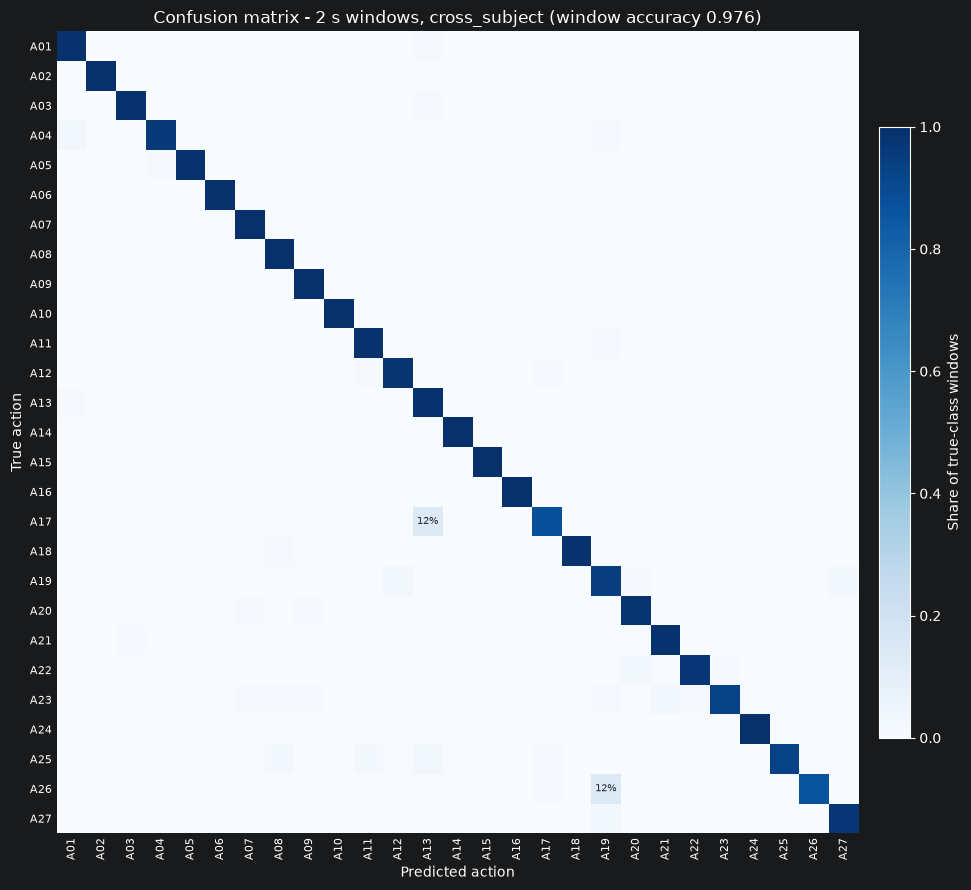

In [31]:
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(direct_confusion_normalised, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(action_codes)), labels=action_codes, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(action_codes)), labels=action_codes, fontsize=8)
ax.set_xlabel("Predicted action")
ax.set_ylabel("True action")
ax.set_title(
    f"Confusion matrix - {WINDOW_SECONDS:g} s windows, {SPLIT_SETTING} "
    f"(window accuracy {direct_metrics['window_accuracy']:.3f})"
)
# Label off-diagonal cells holding at least 5 % of the true class
for true in range(len(action_codes)):
    for predicted in range(len(action_codes)):
        share = direct_confusion_normalised[true, predicted]
        if true != predicted and share >= 0.05:
            # Cells this pale are near-white whatever the notebook theme: force dark ink
            ax.text(predicted, true, f"{share:.0%}", ha="center", va="center", fontsize=7, color="#1f2937")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02, label="Share of true-class windows")
plt.tight_layout()
plt.show()


## 6 - Influence de la durée de fenêtre

Chaque durée demande sa propre extraction (normalisation par fenêtre), puis est rechargée depuis le cache. Une fenêtre plus courte donne plus d'exemples d'entraînement et plus de votes par séquence, mais moins de contexte par fenêtre.

Les fenêtres d'une même séquence sont fortement corrélées : l'unité statistique est la séquence (216) ou le sujet (8), pas la fenêtre. Des écarts de quelques dixièmes de point entre durées ne sont pas significatifs.

In [32]:
WINDOW_EXPERIMENT_SECONDS = [1, 2, 5, 9.5]
experiment_results = []

for window_seconds in WINDOW_EXPERIMENT_SECONDS:
    metrics, _, _ = evaluate_window_seconds(window_seconds, WINDOW_STRIDE_SECONDS)
    experiment_results.append(metrics)
    print(
        f"{window_seconds:g} s: "
        f"window acc={metrics['window_accuracy']:.3f} F1={metrics['window_macro_f1']:.3f} | "
        f"sequence acc={metrics['sequence_accuracy']:.3f} F1={metrics['sequence_macro_f1']:.3f} "
        f"({metrics['train_windows']} train / {metrics['validation_windows']} val windows)"
    )

window_results = pd.DataFrame(experiment_results)
window_results


window features [w1s_s1s]: 100%|██████████| 216/216 [00:01<00:00, 137.20it/s]


1 s: window acc=0.941 F1=0.941 | sequence acc=0.986 F1=0.986 (25056 train / 6264 val windows)


window features [w2s_s2s]: 100%|██████████| 216/216 [00:01<00:00, 174.37it/s]


2 s: window acc=0.976 F1=0.976 | sequence acc=0.991 F1=0.991 (12096 train / 3024 val windows)


window features [w5s_s5s]: 100%|██████████| 216/216 [00:01<00:00, 204.70it/s]


5 s: window acc=0.980 F1=0.980 | sequence acc=0.981 F1=0.981 (4320 train / 1080 val windows)


window features [w9.5s_s9.5s]: 100%|██████████| 216/216 [00:01<00:00, 168.85it/s]


9.5 s: window acc=0.974 F1=0.974 | sequence acc=0.972 F1=0.973 (2592 train / 648 val windows)


,window_seconds,window_frames,train_windows,validation_windows,window_accuracy,window_macro_f1,sequence_accuracy,sequence_macro_f1
0,1.0,10,25056,6264,0.940932,0.941124,0.986111,0.986057
1,2.0,20,12096,3024,0.976190,0.976294,0.990741,0.990704
2,5.0,50,4320,1080,0.979630,0.979676,0.981481,0.981409
3,9.5,95,2592,648,0.973765,0.974073,0.972222,0.972664


## 7 - Fine-tuning partiel de l'encodeur, même SVM

Les 3 derniers blocs Transformer et le `LayerNorm` final sont dégelés et entraînés par entropie croisée (tête linéaire temporaire sur le descripteur mean + max) sur 28 des 32 sujets d'entraînement ; les 4 autres (`SELECTION_SUBJECTS`, un par environnement) ne servent qu'à l'arrêt anticipé. La tête est ensuite jetée : les features par frame sont ré-extraites avec l'encodeur fine-tuné par le même code que la section 5 (`encode_frames`, toutes les frames de la fenêtre), et le même SVM (`StandardScaler` + RBF, C = 1) est entraîné sur les 32 sujets et évalué sur les 8 sujets de validation. Seuls les poids de l'encodeur changent par rapport à la référence. Trois graines.

Le tokenizer (mini-PointNet, BatchNorm), `pos_embed` et les 9 premiers blocs restent gelés en mode eval, pour que la partie gelée produise exactement les features de référence. Augmentations à l'entraînement, identiques pour toutes les frames d'une fenêtre : rotation autour de la verticale (z), échelle isotrope, translation des centres, 10 frames tirées parmi les 20 ; pas de miroir (classes gauche/droite).

Les tokens FPS/kNN de chaque fenêtre sont mis en cache en float16 (`data/pointmae_window_tokens/`, ~4 Go, ~40 min CPU la première fois) ; la référence gelée est ré-extraite depuis ce cache pour vérifier qu'il reproduit le résultat de la section 5.


In [33]:
import copy
import math
import time

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

FINETUNE_BLOCKS = 3               # last Transformer blocks trained (+ final LayerNorm); the rest stays frozen
FINETUNE_EPOCHS = 20
FINETUNE_WARMUP_EPOCHS = 1
FINETUNE_BATCH_WINDOWS = 16
FINETUNE_FRAMES_PER_WINDOW = 10   # random subset of the window's frames at training time (all frames at test time)
FINETUNE_LR_ENCODER = 3e-5
FINETUNE_LR_HEAD = 1e-3
FINETUNE_WEIGHT_DECAY = 0.05
FINETUNE_SEEDS = [0, 1, 2]
# One training subject per environment, used for early stopping only (never the validation subjects)
SELECTION_SUBJECTS = {"S02", "S12", "S22", "S32"}

AUGMENT_ROTATION_DEG = 10.0
AUGMENT_SCALE_RANGE = (0.9, 1.1)
AUGMENT_TRANSLATION = 0.1         # in normalised units (unit sphere)

TOKEN_STRIDE = seconds_to_frames(WINDOW_STRIDE_SECONDS) if WINDOW_STRIDE_SECONDS else None
TOKEN_CACHE_DIR = (
    PROJECT_DIR / "data" / "pointmae_window_tokens"
    / f"{ISOLATION_TAG}_norm-{NORMALISATION_TAG}_g{NUM_GROUP}x{GROUP_SIZE}"
    / f"w{WINDOW_SECONDS:g}s_s{(WINDOW_STRIDE_SECONDS or WINDOW_SECONDS):g}s"
)
FINETUNE_DIR = (
    PROJECT_DIR / "data" / "pointmae_finetune"
    / f"{TOKEN_CACHE_DIR.parent.name}_{TOKEN_CACHE_DIR.name}_last{FINETUNE_BLOCKS}"
)

finetune_sequences = [sequence for sequence in train_sequences if sequence[1] not in SELECTION_SUBJECTS]
selection_sequences = [sequence for sequence in train_sequences if sequence[1] in SELECTION_SUBJECTS]
print(f"Fine-tuning: {len(finetune_sequences)} sequences | selection: {len(selection_sequences)} sequences "
      f"({sorted(SELECTION_SUBJECTS)}) | validation: {len(validation_sequences)} sequences")
print(f"Token cache: {TOKEN_CACHE_DIR}")
print(f"Fine-tuned weights: {FINETUNE_DIR}")


Fine-tuning: 756 sequences | selection: 108 sequences (['S02', 'S12', 'S22', 'S32']) | validation: 216 sequences
Token cache: C:\Users\mbonn\LIARA_2026_internship\data\pointmae_window_tokens\cross_subject_bg-environment_v0.1_t0.8_eps0.25_min5_norm-window_g64x32\w2s_s2s
Fine-tuned weights: C:\Users\mbonn\LIARA_2026_internship\data\pointmae_finetune\cross_subject_bg-environment_v0.1_t0.8_eps0.25_min5_norm-window_g64x32_w2s_s2s_last3


### 7.1 Cache des tokens par fenêtre


In [34]:
def cache_sequence_tokens(sequence, cache_dir=TOKEN_CACHE_DIR):
    """Groups (W, T, G, M, 3) and centres (W, T, G, 3) of every window of the sequence, float16 on disk.
    Same preprocessing as `extract_window_features`."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    stem = "_".join(sequence)
    groups_path, centres_path = cache_dir / f"{stem}_groups.npy", cache_dir / f"{stem}_centres.npy"
    if not (groups_path.exists() and centres_path.exists()):
        isolated = load_isolated_sequence(sequence)
        starts = list(window_starts(len(isolated), WINDOW_LENGTH, TOKEN_STRIDE))
        groups, centres = zip(*(preprocess_window(isolated, start, WINDOW_LENGTH) for start in starts))
        np.save(groups_path, np.stack(groups).astype(np.float16))
        np.save(centres_path, np.stack(centres).astype(np.float16))
    return groups_path, centres_path


for sequence in tqdm(train_sequences + validation_sequences, desc=f"token cache [{TOKEN_CACHE_DIR.name}]"):
    cache_sequence_tokens(sequence)


token cache [w2s_s2s]: 100%|██████████| 1080/1080 [08:01<00:00,  2.24it/s]


### 7.2 Fenêtres augmentées et modèle partiellement dégelé


In [35]:
def augment_window(groups, centres, rng):
    """Same random transform on every frame of the window: rotation about the vertical axis (z),
    isotropic scale, translation of the centres (groups are relative to their centre). No mirroring."""
    angle = np.deg2rad(rng.uniform(-AUGMENT_ROTATION_DEG, AUGMENT_ROTATION_DEG))
    cos, sin = np.cos(angle), np.sin(angle)
    rotation = np.array([[cos, -sin, 0.0], [sin, cos, 0.0], [0.0, 0.0, 1.0]], dtype=np.float32)
    scale = np.float32(rng.uniform(*AUGMENT_SCALE_RANGE))
    translation = rng.uniform(-AUGMENT_TRANSLATION, AUGMENT_TRANSLATION, size=3).astype(np.float32)
    return (groups @ rotation.T) * scale, (centres @ rotation.T) * scale + translation


class WindowTokenDataset(Dataset):
    """Windows of a list of sequences, read from the token cache (memory-mapped)."""

    def __init__(self, sequences, frames_per_window=None, augment=False, rng=None):
        self.items, self.arrays = [], {}
        for sequence in sequences:
            groups_path, centres_path = cache_sequence_tokens(sequence)
            self.arrays[sequence] = (np.load(groups_path, mmap_mode="r"), np.load(centres_path, mmap_mode="r"))
            label = action_to_label[sequence[2]]
            self.items += [(sequence, window, label) for window in range(len(self.arrays[sequence][0]))]
        self.frames_per_window = frames_per_window
        self.augment = augment
        self.rng = rng if rng is not None else np.random.default_rng(0)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        sequence, window, label = self.items[index]
        groups, centres = self.arrays[sequence]
        groups = np.asarray(groups[window], dtype=np.float32)
        centres = np.asarray(centres[window], dtype=np.float32)
        if self.frames_per_window and self.frames_per_window < len(groups):
            keep = np.sort(self.rng.choice(len(groups), self.frames_per_window, replace=False))
            groups, centres = groups[keep], centres[keep]
        if self.augment:
            groups, centres = augment_window(groups, centres, self.rng)
        return torch.from_numpy(np.ascontiguousarray(groups)), torch.from_numpy(np.ascontiguousarray(centres)), label


class PartiallyFinetunedPointMAE(nn.Module):
    """Official encoder with its last `trainable_blocks` blocks (+ final norm) trainable; the tokenizer,
    `pos_embed` and the earlier blocks run frozen, in eval mode. The forward reproduces `encode_frames`
    (mean + max of the tokens per frame), then mean + max over the frames and a linear head (training only)."""

    def __init__(self, encoder, trainable_blocks, num_classes):
        super().__init__()
        self.encoder = encoder
        self.frozen_count = len(encoder.blocks.blocks) - trainable_blocks
        self.head = nn.Linear(4 * encoder.trans_dim, num_classes)
        for parameter in self.encoder.parameters():
            parameter.requires_grad = False
        for block in self.encoder.blocks.blocks[self.frozen_count:]:
            for parameter in block.parameters():
                parameter.requires_grad = True
        for parameter in self.encoder.norm.parameters():
            parameter.requires_grad = True

    def train(self, mode=True):
        # Only the trainable blocks toggle (drop-path); the frozen part, BatchNorm of the tokenizer
        # included, stays in eval mode so that it computes exactly the reference features.
        super().train(False)
        for block in self.encoder.blocks.blocks[self.frozen_count:]:
            block.train(mode)
        self.head.train(mode)
        return self

    def frame_features(self, groups, centres):
        """(F, G, M, 3), (F, G, 3) -> (F, 768), as `encode_frames`."""
        with torch.no_grad():
            tokens = self.encoder.encoder(groups)
            pos = self.encoder.pos_embed(centres)
            for block in self.encoder.blocks.blocks[:self.frozen_count]:
                tokens = block(tokens + pos)
        for block in self.encoder.blocks.blocks[self.frozen_count:]:
            tokens = block(tokens + pos)
        tokens = self.encoder.norm(tokens)
        return torch.cat([tokens.mean(dim=1), tokens.max(dim=1).values], dim=1)

    def forward(self, groups, centres):
        """(B, T, G, M, 3), (B, T, G, 3) -> logits (B, classes)."""
        batch, frames = groups.shape[:2]
        features = self.frame_features(groups.flatten(0, 1), centres.flatten(0, 1)).view(batch, frames, -1)
        return self.head(torch.cat([features.mean(dim=1), features.max(dim=1).values], dim=1))


# Sanity check: with the head aside, the model must reproduce the frozen encoder's features exactly
check_model = PartiallyFinetunedPointMAE(copy.deepcopy(official_pointmae_encoder), FINETUNE_BLOCKS, len(action_codes)).to(DEVICE).eval()
check_groups, check_centres = np.load(TOKEN_CACHE_DIR / ("_".join(train_sequences[0]) + "_groups.npy")), np.load(TOKEN_CACHE_DIR / ("_".join(train_sequences[0]) + "_centres.npy"))
check_groups, check_centres = check_groups[0].astype(np.float32), check_centres[0].astype(np.float32)
with torch.no_grad():
    check_features = check_model.frame_features(torch.from_numpy(check_groups).to(DEVICE), torch.from_numpy(check_centres).to(DEVICE)).cpu().numpy()
check_reference = encode_frames(check_groups, check_centres, official_pointmae_encoder, DEVICE)
trainable_count = sum(parameter.numel() for parameter in check_model.parameters() if parameter.requires_grad)
total_count = sum(parameter.numel() for parameter in check_model.encoder.parameters())
print(f"Max |fine-tuning forward - encode_frames| on one window: {np.abs(check_features - check_reference).max():.2e}")
print(f"Trainable parameters: {trainable_count / 1e6:.2f} M (encoder total {total_count / 1e6:.2f} M, "
      f"last {FINETUNE_BLOCKS} blocks + norm + head)")
del check_model


Max |fine-tuning forward - encode_frames| on one window: 0.00e+00
Trainable parameters: 5.36 M (encoder total 21.83 M, last 3 blocks + norm + head)


### 7.3 Entraînement (arrêt anticipé sur les sujets de sélection)


In [ ]:
def cosine_lr_factor(step, total_steps, warmup_steps):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * progress))


def evaluate_head(model, loader):
    """Window accuracy of the temporary head (all frames of each window, no augmentation)."""
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for groups, centres, labels in loader:
            logits = model(groups.to(DEVICE), centres.to(DEVICE))
            correct += (logits.argmax(dim=1).cpu() == labels).sum().item()
            total += len(labels)
    return correct / total


def finetune(seed):
    """Partial fine-tuning on `finetune_sequences` with early stopping on `selection_sequences`.
    Returns the path of the best encoder weights and the training history (both cached on disk)."""
    FINETUNE_DIR.mkdir(parents=True, exist_ok=True)
    weights_path = FINETUNE_DIR / f"seed{seed}_encoder.pt"
    history_path = FINETUNE_DIR / f"seed{seed}_history.csv"
    if weights_path.exists() and history_path.exists():
        return weights_path, pd.read_csv(history_path)

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = PartiallyFinetunedPointMAE(
        copy.deepcopy(official_pointmae_encoder), FINETUNE_BLOCKS, len(action_codes)
    ).to(DEVICE)
    train_loader = DataLoader(
        WindowTokenDataset(finetune_sequences, FINETUNE_FRAMES_PER_WINDOW, augment=True, rng=rng),
        batch_size=FINETUNE_BATCH_WINDOWS, shuffle=True, drop_last=True,
        generator=torch.Generator().manual_seed(seed),
    )
    selection_loader = DataLoader(WindowTokenDataset(selection_sequences), batch_size=FINETUNE_BATCH_WINDOWS)

    optimizer = torch.optim.AdamW(
        [
            {"params": [p for p in model.encoder.parameters() if p.requires_grad], "lr": FINETUNE_LR_ENCODER},
            {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD},
        ],
        weight_decay=FINETUNE_WEIGHT_DECAY,
    )
    total_steps = FINETUNE_EPOCHS * len(train_loader)
    warmup_steps = FINETUNE_WARMUP_EPOCHS * len(train_loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: cosine_lr_factor(step, total_steps, warmup_steps)
    )

    history, best_accuracy, best_state = [], -1.0, None
    for epoch in range(FINETUNE_EPOCHS):
        model.train()
        losses, start_time = [], time.time()
        for groups, centres, labels in train_loader:
            logits = model(groups.to(DEVICE), centres.to(DEVICE))
            loss = F.cross_entropy(logits, labels.to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())
        selection_accuracy = evaluate_head(model, selection_loader)
        history.append({"seed": seed, "epoch": epoch + 1, "train_loss": float(np.mean(losses)),
                        "selection_window_accuracy": selection_accuracy, "seconds": time.time() - start_time})
        print(f"seed {seed} epoch {epoch + 1:2d}/{FINETUNE_EPOCHS}: loss {np.mean(losses):.3f}, "
              f"selection window acc {selection_accuracy:.3f} ({time.time() - start_time:.0f} s)")
        if selection_accuracy > best_accuracy:
            best_accuracy = selection_accuracy
            best_state = {key: value.detach().cpu().clone() for key, value in model.encoder.state_dict().items()}

    torch.save(best_state, weights_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    return weights_path, pd.DataFrame(history)


finetune_histories = {}
for seed in FINETUNE_SEEDS:
    _, finetune_histories[seed] = finetune(seed)
    best = finetune_histories[seed].loc[finetune_histories[seed]["selection_window_accuracy"].idxmax()]
    print(f"seed {seed}: best selection window acc {best['selection_window_accuracy']:.3f} at epoch {int(best['epoch'])}")


seed 0 epoch  1/20: loss 2.399, selection window acc 0.856 (293 s)
seed 0 epoch  2/20: loss 0.231, selection window acc 0.898 (273 s)
seed 0 epoch  3/20: loss 0.072, selection window acc 0.914 (272 s)
seed 0 epoch  4/20: loss 0.054, selection window acc 0.926 (274 s)
seed 0 epoch  5/20: loss 0.035, selection window acc 0.923 (272 s)
seed 0 epoch  6/20: loss 0.027, selection window acc 0.913 (272 s)
seed 0 epoch  7/20: loss 0.026, selection window acc 0.919 (272 s)
seed 0 epoch  8/20: loss 0.016, selection window acc 0.924 (272 s)


### 7.4 Features de l'encodeur fine-tuné et SVM de référence


In [ ]:
def extract_cached_window_features(encoder_state, sequences):
    """Per-frame features of every cached window (all frames, no augmentation) with the given encoder
    weights, through `encode_frames` exactly as in section 5: list of (n_windows, T, 768) arrays."""
    encoder = copy.deepcopy(official_pointmae_encoder)
    encoder.load_state_dict(encoder_state)
    encoder.eval()
    features = []
    for sequence in tqdm(sequences, desc="features", leave=False):
        groups_path, centres_path = cache_sequence_tokens(sequence)
        groups, centres = np.load(groups_path).astype(np.float32), np.load(centres_path).astype(np.float32)
        frame_features = encode_frames(groups.reshape(-1, *groups.shape[2:]), centres.reshape(-1, *centres.shape[2:]), encoder, DEVICE)
        features.append(frame_features.reshape(len(groups), groups.shape[1], -1))
    return features


def evaluate_svm_with(encoder_state, C=1.0):
    """Same protocol as `evaluate_window_seconds`: SVM on all training windows, validation windows and sequences."""
    train_features, train_labels, _ = build_window_features(
        extract_cached_window_features(encoder_state, train_sequences), train_sequence_labels
    )
    validation_windows = extract_cached_window_features(encoder_state, validation_sequences)
    validation_features, validation_labels, validation_ids = build_window_features(
        validation_windows, validation_sequence_labels
    )
    svm = Pipeline([("scaler", StandardScaler()), ("classifier", SVC(kernel="rbf", C=C))])
    svm.fit(train_features, train_labels)
    window_predictions = svm.predict(validation_features)
    sequence_predictions = sequence_vote(window_predictions, validation_ids, len(validation_windows))
    metrics = {
        "window_accuracy": accuracy_score(validation_labels, window_predictions),
        "window_macro_f1": f1_score(validation_labels, window_predictions, average="macro"),
        "sequence_accuracy": accuracy_score(validation_sequence_labels, sequence_predictions),
        "sequence_macro_f1": f1_score(validation_sequence_labels, sequence_predictions, average="macro"),
    }
    return metrics, (validation_labels, window_predictions, sequence_predictions)


finetune_results, finetune_predictions = [], {}

# Reference: frozen encoder, features re-extracted from the float16 token cache (must match section 5)
metrics, finetune_predictions["frozen"] = evaluate_svm_with(official_pointmae_encoder.state_dict())
finetune_results.append({"encoder": "frozen (token cache)", "seed": None, "best_epoch": None, **metrics})
print(f"frozen: window acc {metrics['window_accuracy']:.3f} | sequence acc {metrics['sequence_accuracy']:.3f}")

for seed in FINETUNE_SEEDS:
    weights_path, history = finetune(seed)
    best_epoch = int(history.loc[history["selection_window_accuracy"].idxmax(), "epoch"])
    metrics, finetune_predictions[seed] = evaluate_svm_with(torch.load(weights_path, map_location=DEVICE))
    finetune_results.append({"encoder": f"fine-tuned (last {FINETUNE_BLOCKS} blocks)", "seed": seed, "best_epoch": best_epoch, **metrics})
    print(f"seed {seed}: window acc {metrics['window_accuracy']:.3f} | sequence acc {metrics['sequence_accuracy']:.3f}")

finetune_table = pd.DataFrame(finetune_results)
finetuned_rows = finetune_table[finetune_table["seed"].notna()]
print()
print(f"fine-tuned, {len(finetuned_rows)} seeds: window acc {finetuned_rows['window_accuracy'].mean():.3f} ± {finetuned_rows['window_accuracy'].std():.3f} | "
      f"sequence acc {finetuned_rows['sequence_accuracy'].mean():.3f} ± {finetuned_rows['sequence_accuracy'].std():.3f}")
finetune_table


### Courbes d'entraînement


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for seed, history in finetune_histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=f"seed {seed}")
    axes[1].plot(history["epoch"], history["selection_window_accuracy"], label=f"seed {seed}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("train loss (cross-entropy)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("selection window accuracy (head)")
axes[1].axhline(finetune_table.loc[0, "window_accuracy"], color="grey", linestyle="--", label="frozen + SVM (validation)")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
